# ORPO: Monolithic Preference Optimization without Reference Model (ORPO)

**Paper:** [arXiv:2403.07691](https://arxiv.org/abs/2403.07691)
**Authors:** Jiwoo Hong, Noah Lee, James Thorne (2024; preprint)

This notebook implements the ORPO loss from scratch in PyTorch, on a tiny character-level GRU language model.
ORPO combines supervised fine-tuning (SFT) and preference alignment into a single training stage —
no reference model needed. The key idea is an odds-ratio penalty that pushes down the likelihood
of rejected responses while the SFT loss pushes up the likelihood of chosen responses.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Synthetic preference-pair data instead of HH-RLHF / UltraFeedback
- A 2-layer GRU with 179K parameters instead of OPT-125M to Mistral-7B
- 50 epochs with AdamW (lr 5e-4) instead of the paper's single-epoch full-scale fine-tuning
- λ = 0.5 (paper uses 0.1–0.25 depending on model)

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt   # keep the inline backend so plots display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
EPOCHS = 50
BATCH_SIZE = 32
LR = 5e-4
LAMBDA = 0.5          # weighting for the odds-ratio loss (paper uses 0.1-0.25)
EMBED_DIM = 64
HIDDEN_DIM = 128
N_LAYERS = 2
SEQ_LEN = 20
PROMPT_LEN = 5
VOCAB_SIZE = 30
N_TRAIN = 400         # preference pairs
N_TEST = 100          # preference pairs
SFT_EPOCHS = 30       # pre-SFT for the DPO baseline's reference model

Device: cuda


## 2. Synthetic Preference Data

ORPO requires **paired preference data**: for each prompt, a chosen response $y_w$ and a rejected
response $y_l$. We create synthetic data where chosen completions follow a repetitive pattern
(e.g. alternating characters) and rejected completions are random noise. The prompt is a short
random sequence. This gives the odds-ratio loss a clear signal: the model should learn to assign
higher odds to patterned completions and lower odds to random ones — all within a single
training stage, with no reference model.

In [2]:
def generate_preference_data(n_examples, prompt_len, seq_len, vocab_size, seed=0):
    """Generate synthetic preference-pair data.

    Chosen completions follow a repetitive pattern (alternating two characters).
    Rejected completions are random sequences from the same vocabulary.
    Returns (prompts, chosen, rejected).
    """
    rng = np.random.RandomState(seed)
    prompts, chosen_list, rejected_list = [], [], []
    for i in range(n_examples):
        prompt = rng.randint(2, vocab_size, size=prompt_len).tolist()
        # Chosen: repetitive pattern
        a, b = rng.randint(2, vocab_size), rng.randint(2, vocab_size)
        ch = [a, b] * (seq_len // 2)
        if len(ch) < seq_len:
            ch.append(a)
        # Rejected: random noise
        rj = rng.randint(2, vocab_size, size=seq_len).tolist()
        prompts.append(prompt)
        chosen_list.append(ch)
        rejected_list.append(rj)
    return prompts, chosen_list, rejected_list

# Generate training and test data
train_prompts, train_chosen, train_rejected = generate_preference_data(
    N_TRAIN, PROMPT_LEN, SEQ_LEN, VOCAB_SIZE, seed=0)
test_prompts, test_chosen, test_rejected = generate_preference_data(
    N_TEST, PROMPT_LEN, SEQ_LEN, VOCAB_SIZE, seed=42)

# Convert to tensors
train_prompt_t = torch.tensor(train_prompts, dtype=torch.long)
train_chosen_t = torch.tensor(train_chosen, dtype=torch.long)
train_rejected_t = torch.tensor(train_rejected, dtype=torch.long)
test_prompt_t = torch.tensor(test_prompts, dtype=torch.long)
test_chosen_t = torch.tensor(test_chosen, dtype=torch.long)
test_rejected_t = torch.tensor(test_rejected, dtype=torch.long)

print(f"Training pairs: {N_TRAIN}, Test pairs: {N_TEST}")
print(f"Vocab size: {VOCAB_SIZE}, Prompt length: {PROMPT_LEN}, Completion length: {SEQ_LEN}")
print(f"Example prompt: {train_prompts[0]}")
print(f"Example chosen: {train_chosen[0]}")
print(f"Example rejected: {train_rejected[0]}")

Training pairs: 400, Test pairs: 100
Vocab size: 30, Prompt length: 5, Completion length: 20
Example prompt: [14, 17, 23, 2, 5]
Example chosen: [29, 5, 29, 5, 29, 5, 29, 5, 29, 5, 29, 5, 29, 5, 29, 5, 29, 5, 29, 5]
Example rejected: [9, 11, 21, 23, 20, 6, 25, 8, 26, 26, 14, 28, 3, 8, 9, 25, 16, 26, 19, 7]


## 3. Character-Level GRU Language Model

A tiny GRU-based language model. The model takes a sequence of token IDs and returns
logits at each position. We compute the total log-probability of a completion by
concatenating the prompt and completion, then reading off the log-softmax of the
completion tokens.

In [3]:
class TinyLM(nn.Module):
    """Character-level GRU language model."""
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim)
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=n_layers,
                          batch_first=True)
        self.proj = nn.Linear(hidden_dim, vocab_size)

    def forward(self, tokens):
        """tokens: (batch, seq_len) LongTensor. Returns logits: (batch, seq_len, vocab)."""
        emb = self.embed(tokens)          # (batch, seq, embed)
        out, _ = self.gru(emb)            # (batch, seq, hidden)
        logits = self.proj(out)           # (batch, seq, vocab)
        return logits


def compute_logps(model, prompt, completion):
    """Compute total log-probability of completions given prompts.

    Args:
        model: TinyLM
        prompt: (B, prompt_len) LongTensor
        completion: (B, seq_len) LongTensor
    Returns:
        logps: (B,) total log-probability of each completion
    """
    full = torch.cat([prompt, completion], dim=1)  # (B, prompt_len + seq_len)
    logits = model(full)  # (B, full_len, vocab)

    # We want log-probs of the completion tokens.
    # The logits at position (prompt_len - 1 + i) predict completion token i.
    # So we shift: logits at positions [prompt_len-1 : prompt_len-1+seq_len] predict completion.
    completion_logits = logits[:, PROMPT_LEN - 1: PROMPT_LEN - 1 + SEQ_LEN, :]  # (B, seq_len, vocab)
    log_probs = F.log_softmax(completion_logits, dim=-1)  # (B, seq_len, vocab)

    # Gather log-probs of the actual completion tokens
    completion_tokens = completion.unsqueeze(-1)  # (B, seq_len, 1)
    token_logps = log_probs.gather(-1, completion_tokens).squeeze(-1)  # (B, seq_len)
    return token_logps.sum(dim=1)  # (B,) total log-prob


model = TinyLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 179,358


## 4. ORPO Loss

The ORPO objective (Eq. 6) combines two terms:

$$\mathcal{L}_{ORPO} = \mathbb{E}_{(x, y_w, y_l)}\left[\mathcal{L}_{SFT} + \lambda \cdot \mathcal{L}_{OR}\right]$$

- **$\mathcal{L}_{SFT}$**: the standard causal LM negative log-likelihood on the **chosen** response $y_w$.
  This adapts the model to the desired domain, just like ordinary SFT.
- **$\mathcal{L}_{OR}$** (Eq. 7): an odds-ratio penalty that contrasts the odds of the chosen
  response against the rejected response:

$$\mathcal{L}_{OR} = -\log\sigma\left(\log\frac{\text{odds}_\theta(y_w | x)}{\text{odds}_\theta(y_l | x)}\right)$$

where $\text{odds}_\theta(y | x) = \frac{P_\theta(y | x)}{1 - P_\theta(y | x)}$.

**Key difference from DPO**: no reference model is needed. DPO uses the log-ratio
$\log \pi_\theta(y|x) / \pi_{ref}(y|x)$, which requires a frozen reference model.
ORPO replaces this with the odds ratio, which only needs the current model's probabilities.
This halves the number of forward passes per batch (2 instead of 4).

In [4]:
def compute_odds(model, prompt, completion):
    """Compute odds = P/(1-P) for a batch of completions.

    Uses geometric mean of per-token probabilities as the sequence probability.
    Returns: (B,) odds tensor (differentiable)
    """
    logps = compute_logps(model, prompt, completion)  # (B,)
    avg_logp = logps / SEQ_LEN
    p = torch.exp(avg_logp)  # geometric mean per-token prob
    odds = p / (1 - p + 1e-8)
    return odds, logps


def orpo_loss(model, prompt, chosen, rejected, lam):
    """Compute the ORPO loss and metrics.

    Args:
        model: TinyLM (the policy, also used for SFT)
        prompt: (B, prompt_len) LongTensor
        chosen: (B, seq_len) LongTensor  -- y_w
        rejected: (B, seq_len) LongTensor -- y_l
        lam: weighting for the odds-ratio loss
    Returns:
        loss: scalar, total ORPO loss
        metrics: dict with component losses and odds ratio
    """
    # SFT loss: NLL on chosen response
    chosen_logps = compute_logps(model, prompt, chosen)  # (B,)
    sft_loss = -chosen_logps.mean()

    # Odds ratio loss (differentiable)
    chosen_odds, _ = compute_odds(model, prompt, chosen)
    rejected_odds, rejected_logps = compute_odds(model, prompt, rejected)

    log_or = torch.log(chosen_odds + 1e-8) - torch.log(rejected_odds + 1e-8)
    or_loss = -F.logsigmoid(log_or).mean()

    # Total loss
    total_loss = sft_loss + lam * or_loss

    with torch.no_grad():
        metrics = {
            'sft_loss': sft_loss.item(),
            'or_loss': or_loss.item(),
            'total_loss': total_loss.item(),
            'log_odds_ratio': log_or.mean().item(),
            'chosen_logp': chosen_logps.mean().item(),
            'rejected_logp': rejected_logps.mean().item(),
        }
    return total_loss, metrics

## 5. DPO Loss (for Comparison)

We also implement the DPO loss to compare ORPO vs DPO on the same data.
DPO requires a frozen reference model, so we pre-train one on the chosen completions (SFT stage).
DPO uses the log-ratio between the policy and reference model — which is exactly what ORPO
eliminates.

In [5]:
def dpo_loss(policy_chosen_logps, policy_rejected_logps,
             ref_chosen_logps, ref_rejected_logps, beta=0.1):
    """Compute DPO loss and implicit rewards.

    L_DPO = -E[log sigma(beta * (log(pi(y_w)/pi_ref(y_w)) - log(pi(y_l)/pi_ref(y_l))))]
    """
    pi_logratios = policy_chosen_logps - policy_rejected_logps
    ref_logratios = ref_chosen_logps - ref_rejected_logps
    logits = beta * (pi_logratios - ref_logratios)
    loss = -F.logsigmoid(logits).mean()

    with torch.no_grad():
        chosen_rewards = beta * (policy_chosen_logps - ref_chosen_logps)
        rejected_rewards = beta * (policy_rejected_logps - ref_rejected_logps)
        metrics = {
            'loss': loss.item(),
            'reward_margin': (chosen_rewards - rejected_rewards).mean().item(),
            'accuracy': (chosen_rewards > rejected_rewards).float().mean().item(),
        }
    return loss, metrics


# Pre-train a reference model on chosen completions (SFT stage for DPO)
ref_model = TinyLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS).to(DEVICE)
ref_optimizer = optim.AdamW(ref_model.parameters(), lr=1e-3)

for epoch in range(1, SFT_EPOCHS + 1):
    ref_model.train()
    perm = torch.randperm(N_TRAIN)
    n_batches = (N_TRAIN + BATCH_SIZE - 1) // BATCH_SIZE
    epoch_loss = 0.0
    for b in range(n_batches):
        idx = perm[b * BATCH_SIZE:(b + 1) * BATCH_SIZE]
        p = train_prompt_t[idx].to(DEVICE)
        c = train_chosen_t[idx].to(DEVICE)
        logps = compute_logps(ref_model, p, c)
        loss = -logps.mean()
        ref_optimizer.zero_grad()
        loss.backward()
        ref_optimizer.step()
        epoch_loss += loss.item()
    if epoch == 1 or epoch % 10 == 0:
        print(f"Ref SFT Epoch [{epoch:3d}/{SFT_EPOCHS}]  loss {epoch_loss / n_batches:.4f}")

# Initialize DPO policy from the reference model
dpo_model = TinyLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS).to(DEVICE)
dpo_model.load_state_dict(ref_model.state_dict())

print(f"\nReference model parameters: {sum(p.numel() for p in ref_model.parameters()):,}")

Ref SFT Epoch [  1/30]  loss 64.2244


Ref SFT Epoch [ 10/30]  loss 25.2822


Ref SFT Epoch [ 20/30]  loss 9.0047


Ref SFT Epoch [ 30/30]  loss 4.9212

Reference model parameters: 179,358


## 6. Training Loop

We train two models with identical architecture:
- **ORPO model:** trained with the ORPO loss (SFT + odds-ratio penalty, no reference model)
- **DPO model:** trained with DPO loss using the pre-trained reference model

Both use the same optimizer, learning rate, and number of epochs for a fair comparison.
The ORPO model does NOT need the reference model at all — that is the whole point.

In [6]:
# Prepare data on device
train_prompt_d = train_prompt_t.to(DEVICE)
train_chosen_d = train_chosen_t.to(DEVICE)
train_rejected_d = train_rejected_t.to(DEVICE)
test_prompt_d = test_prompt_t.to(DEVICE)
test_chosen_d = test_chosen_t.to(DEVICE)
test_rejected_d = test_rejected_t.to(DEVICE)

# Initialize ORPO model (random init - no SFT warmup needed!)
orpo_model = TinyLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS).to(DEVICE)

orpo_optimizer = optim.AdamW(orpo_model.parameters(), lr=LR)
dpo_optimizer = optim.AdamW(dpo_model.parameters(), lr=LR)

orpo_history = {'loss': [], 'sft_loss': [], 'or_loss': [], 'log_odds_ratio': [],
                'chosen_logp': [], 'rejected_logp': [], 'test_acc': []}
dpo_history = {'loss': [], 'reward_margin': [], 'test_acc': []}

n_batches = (N_TRAIN + BATCH_SIZE - 1) // BATCH_SIZE

BETA_DPO = 0.1  # DPO temperature

start = time.time()
for epoch in range(1, EPOCHS + 1):
    # --- ORPO training ---
    orpo_model.train()
    perm = torch.randperm(N_TRAIN)
    epoch_total, epoch_sft, epoch_or = 0.0, 0.0, 0.0
    epoch_lor, epoch_chosen_lp, epoch_rejected_lp = 0.0, 0.0, 0.0

    for b in range(n_batches):
        idx = perm[b * BATCH_SIZE:(b + 1) * BATCH_SIZE]
        p = train_prompt_d[idx]
        ch = train_chosen_d[idx]
        rj = train_rejected_d[idx]

        loss, m = orpo_loss(orpo_model, p, ch, rj, LAMBDA)
        orpo_optimizer.zero_grad()
        loss.backward()
        orpo_optimizer.step()

        epoch_total += m['total_loss']
        epoch_sft += m['sft_loss']
        epoch_or += m['or_loss']
        epoch_lor += m['log_odds_ratio']
        epoch_chosen_lp += m['chosen_logp']
        epoch_rejected_lp += m['rejected_logp']

    orpo_history['loss'].append(epoch_total / n_batches)
    orpo_history['sft_loss'].append(epoch_sft / n_batches)
    orpo_history['or_loss'].append(epoch_or / n_batches)
    orpo_history['log_odds_ratio'].append(epoch_lor / n_batches)
    orpo_history['chosen_logp'].append(epoch_chosen_lp / n_batches)
    orpo_history['rejected_logp'].append(epoch_rejected_lp / n_batches)

    # --- DPO training ---
    dpo_model.train()
    ref_model.eval()
    epoch_dpo_loss, epoch_dpo_margin = 0.0, 0.0

    for b in range(n_batches):
        idx = perm[b * BATCH_SIZE:(b + 1) * BATCH_SIZE]
        p = train_prompt_d[idx]
        ch = train_chosen_d[idx]
        rj = train_rejected_d[idx]

        with torch.no_grad():
            ref_chosen = compute_logps(ref_model, p, ch)
            ref_rejected = compute_logps(ref_model, p, rj)

        pol_chosen = compute_logps(dpo_model, p, ch)
        pol_rejected = compute_logps(dpo_model, p, rj)

        loss, dm = dpo_loss(pol_chosen, pol_rejected, ref_chosen, ref_rejected, BETA_DPO)
        dpo_optimizer.zero_grad()
        loss.backward()
        dpo_optimizer.step()

        epoch_dpo_loss += dm['loss']
        epoch_dpo_margin += dm['reward_margin']

    dpo_history['loss'].append(epoch_dpo_loss / n_batches)
    dpo_history['reward_margin'].append(epoch_dpo_margin / n_batches)

    # --- Test accuracy (every 5 epochs) ---
    if epoch == 1 or epoch % 5 == 0:
        orpo_model.eval()
        dpo_model.eval()
        with torch.no_grad():
            # ORPO: odds ratio > 0 means chosen is preferred
            o_chosen_lp = compute_logps(orpo_model, test_prompt_d, test_chosen_d)
            o_rejected_lp = compute_logps(orpo_model, test_prompt_d, test_rejected_d)
            o_chosen_p = torch.exp(o_chosen_lp / SEQ_LEN)
            o_rejected_p = torch.exp(o_rejected_lp / SEQ_LEN)
            o_chosen_odds = o_chosen_p / (1 - o_chosen_p + 1e-8)
            o_rejected_odds = o_rejected_p / (1 - o_rejected_p + 1e-8)
            orpo_acc = (o_chosen_odds > o_rejected_odds).float().mean().item()

            # DPO: reward margin > 0 means chosen is preferred
            d_ref_ch = compute_logps(ref_model, test_prompt_d, test_chosen_d)
            d_ref_rj = compute_logps(ref_model, test_prompt_d, test_rejected_d)
            d_pol_ch = compute_logps(dpo_model, test_prompt_d, test_chosen_d)
            d_pol_rj = compute_logps(dpo_model, test_prompt_d, test_rejected_d)
            d_chosen_r = BETA_DPO * (d_pol_ch - d_ref_ch)
            d_rejected_r = BETA_DPO * (d_pol_rj - d_ref_rj)
            dpo_acc = (d_chosen_r > d_rejected_r).float().mean().item()

        orpo_history['test_acc'].append(orpo_acc)
        dpo_history['test_acc'].append(dpo_acc)
        print(f"Epoch [{epoch:3d}/{EPOCHS}]  "
              f"ORPO loss {orpo_history['loss'][-1]:.4f} (SFT {orpo_history['sft_loss'][-1]:.4f}, OR {orpo_history['or_loss'][-1]:.4f})  "
              f"ORPO acc {orpo_acc:.2%}  DPO acc {dpo_acc:.2%}  "
              f"[{time.time() - start:.0f}s]")

print(f"\nTraining time: {time.time() - start:.0f}s")

Epoch [  1/50]  ORPO loss 66.2954 (SFT 65.9740, OR 0.6429)  ORPO acc 100.00%  DPO acc 100.00%  [0s]


Epoch [  5/50]  ORPO loss 42.8006 (SFT 42.6958, OR 0.2098)  ORPO acc 100.00%  DPO acc 100.00%  [1s]


Epoch [ 10/50]  ORPO loss 30.2480 (SFT 30.2120, OR 0.0720)  ORPO acc 100.00%  DPO acc 100.00%  [2s]


Epoch [ 15/50]  ORPO loss 26.2565 (SFT 26.2339, OR 0.0451)  ORPO acc 100.00%  DPO acc 100.00%  [3s]


Epoch [ 20/50]  ORPO loss 21.9449 (SFT 21.9306, OR 0.0285)  ORPO acc 100.00%  DPO acc 100.00%  [4s]


Epoch [ 25/50]  ORPO loss 13.9889 (SFT 13.9833, OR 0.0114)  ORPO acc 100.00%  DPO acc 100.00%  [5s]


Epoch [ 30/50]  ORPO loss 10.3773 (SFT 10.3745, OR 0.0055)  ORPO acc 100.00%  DPO acc 100.00%  [5s]


Epoch [ 35/50]  ORPO loss 8.6251 (SFT 8.6233, OR 0.0037)  ORPO acc 100.00%  DPO acc 100.00%  [6s]


Epoch [ 40/50]  ORPO loss 7.4730 (SFT 7.4716, OR 0.0027)  ORPO acc 100.00%  DPO acc 100.00%  [7s]


Epoch [ 45/50]  ORPO loss 6.3907 (SFT 6.3896, OR 0.0021)  ORPO acc 100.00%  DPO acc 100.00%  [8s]


Epoch [ 50/50]  ORPO loss 5.4679 (SFT 5.4671, OR 0.0016)  ORPO acc 100.00%  DPO acc 100.00%  [9s]

Training time: 9s


## 7. Training Curves

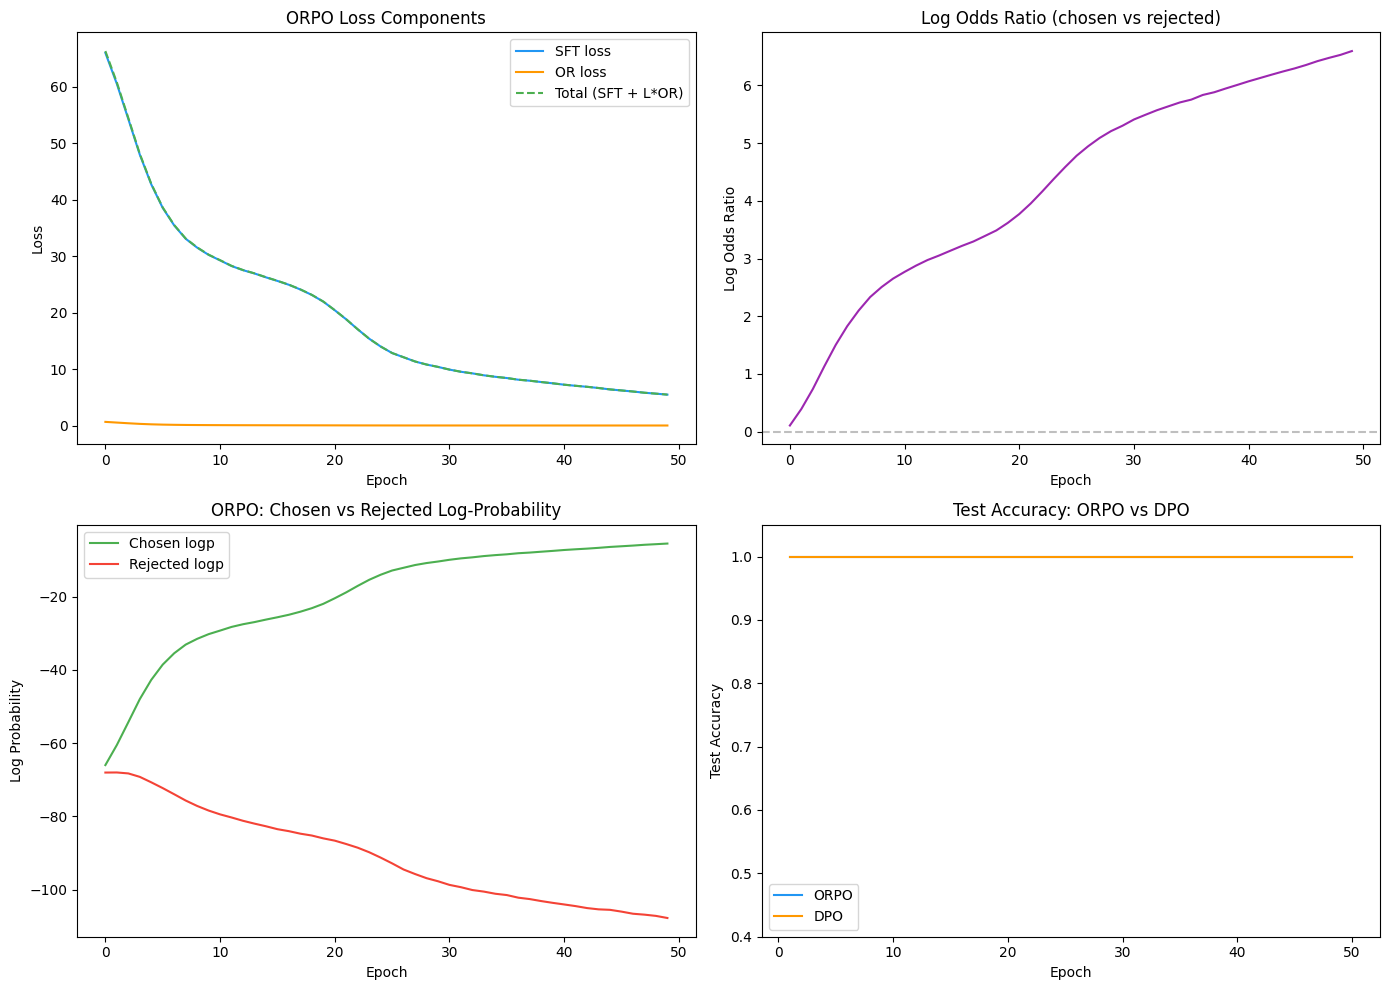

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ORPO loss components
axes[0, 0].plot(orpo_history['sft_loss'], label='SFT loss', color='#2196F3')
axes[0, 0].plot(orpo_history['or_loss'], label='OR loss', color='#FF9800')
axes[0, 0].plot(orpo_history['loss'], label='Total (SFT + L*OR)', color='#4CAF50', linestyle='--')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('ORPO Loss Components')
axes[0, 0].legend()

# Log odds ratio
axes[0, 1].plot(orpo_history['log_odds_ratio'], color='#9C27B0')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Log Odds Ratio')
axes[0, 1].set_title('Log Odds Ratio (chosen vs rejected)')
axes[0, 1].axhline(y=0, color='gray', linestyle='--', alpha=0.5)

# Chosen vs rejected log-probs
axes[1, 0].plot(orpo_history['chosen_logp'], label='Chosen logp', color='#4CAF50')
axes[1, 0].plot(orpo_history['rejected_logp'], label='Rejected logp', color='#F44336')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Log Probability')
axes[1, 0].set_title('ORPO: Chosen vs Rejected Log-Probability')
axes[1, 0].legend()

# Test accuracy comparison
epochs_recorded = [1] + list(range(5, EPOCHS + 1, 5))
if len(epochs_recorded) > len(orpo_history['test_acc']):
    epochs_recorded = epochs_recorded[:len(orpo_history['test_acc'])]
axes[1, 1].plot(epochs_recorded, orpo_history['test_acc'], label='ORPO', color='#2196F3')
axes[1, 1].plot(epochs_recorded, dpo_history['test_acc'], label='DPO', color='#FF9800')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Test Accuracy')
axes[1, 1].set_title('Test Accuracy: ORPO vs DPO')
axes[1, 1].legend()
axes[1, 1].set_ylim(0.4, 1.05)

plt.tight_layout()
plt.show()

## 8. Final Evaluation

We compare ORPO and DPO on the test set. The key metric is **preference accuracy**:
does the model assign higher odds (ORPO) or higher reward (DPO) to the chosen
response than to the rejected response?

**Key point:** ORPO achieves this without any reference model, while DPO requires
a pre-trained reference model and twice as many forward passes per batch.

In [8]:
orpo_model.eval()
dpo_model.eval()

with torch.no_grad():
    # --- ORPO metrics ---
    o_chosen_lp = compute_logps(orpo_model, test_prompt_d, test_chosen_d)
    o_rejected_lp = compute_logps(orpo_model, test_prompt_d, test_rejected_d)
    o_chosen_p = torch.exp(o_chosen_lp / SEQ_LEN)
    o_rejected_p = torch.exp(o_rejected_lp / SEQ_LEN)
    o_chosen_odds = o_chosen_p / (1 - o_chosen_p + 1e-8)
    o_rejected_odds = o_rejected_p / (1 - o_rejected_p + 1e-8)
    orpo_acc = (o_chosen_odds > o_rejected_odds).float().mean().item()
    orpo_log_or = (torch.log(o_chosen_odds + 1e-8) - torch.log(o_rejected_odds + 1e-8)).mean().item()
    orpo_chosen_lp = o_chosen_lp.mean().item()
    orpo_rejected_lp = o_rejected_lp.mean().item()

    # --- DPO metrics ---
    d_ref_ch = compute_logps(ref_model, test_prompt_d, test_chosen_d)
    d_ref_rj = compute_logps(ref_model, test_prompt_d, test_rejected_d)
    d_pol_ch = compute_logps(dpo_model, test_prompt_d, test_chosen_d)
    d_pol_rj = compute_logps(dpo_model, test_prompt_d, test_rejected_d)
    d_chosen_r = BETA_DPO * (d_pol_ch - d_ref_ch)
    d_rejected_r = BETA_DPO * (d_pol_rj - d_ref_rj)
    dpo_acc = (d_chosen_r > d_rejected_r).float().mean().item()
    dpo_margin = (d_chosen_r - d_rejected_r).mean().item()

    # Baseline (untrained): random init model
    baseline_model = TinyLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS).to(DEVICE)
    torch.manual_seed(999)
    b_chosen_lp = compute_logps(baseline_model, test_prompt_d, test_chosen_d)
    b_rejected_lp = compute_logps(baseline_model, test_prompt_d, test_rejected_d)
    b_chosen_p = torch.exp(b_chosen_lp / SEQ_LEN)
    b_rejected_p = torch.exp(b_rejected_lp / SEQ_LEN)
    b_chosen_odds = b_chosen_p / (1 - b_chosen_p + 1e-8)
    b_rejected_odds = b_rejected_p / (1 - b_rejected_p + 1e-8)
    baseline_acc = (b_chosen_odds > b_rejected_odds).float().mean().item()

print(f"ORPO test accuracy: {orpo_acc:.4f}")
print(f"DPO test accuracy: {dpo_acc:.4f}")
print(f"Baseline (untrained) accuracy: {baseline_acc:.4f}")
print(f"ORPO log odds ratio: {orpo_log_or:.4f}")
print(f"ORPO chosen logp: {orpo_chosen_lp:.4f}")
print(f"ORPO rejected logp: {orpo_rejected_lp:.4f}")
print(f"ORPO logp margin: {orpo_chosen_lp - orpo_rejected_lp:.4f}")
print(f"DPO reward margin: {dpo_margin:.4f}")
print(f"ORPO forward passes per batch: 2 (chosen + rejected, no reference model)")
print(f"DPO forward passes per batch: 4 (policy chosen + policy rejected + ref chosen + ref rejected)")

ORPO test accuracy: 1.0000
DPO test accuracy: 1.0000
Baseline (untrained) accuracy: 0.4500
ORPO log odds ratio: 5.4496
ORPO chosen logp: -13.4929
ORPO rejected logp: -106.9477
ORPO logp margin: 93.4548
DPO reward margin: 6.5050
ORPO forward passes per batch: 2 (chosen + rejected, no reference model)
DPO forward passes per batch: 4 (policy chosen + policy rejected + ref chosen + ref rejected)


## 9. Ablation: Effect of lambda (Odds-Ratio Weight)

The paper studies how lambda controls the trade-off between SFT adaptation and
preference alignment. We train ORPO with three values of lambda and compare.
The paper uses lambda = 0.1 for Mistral, 0.2 for Llama-2, and 0.25 for Phi-2.

In [9]:
lambdas = [0.1, 0.5, 1.0]
ablation_results = {}

for lam_val in lambdas:
    abl_model = TinyLM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, N_LAYERS).to(DEVICE)
    abl_optimizer = optim.AdamW(abl_model.parameters(), lr=LR)

    for epoch in range(EPOCHS):
        abl_model.train()
        perm = torch.randperm(N_TRAIN)
        for b in range(n_batches):
            idx = perm[b * BATCH_SIZE:(b + 1) * BATCH_SIZE]
            p = train_prompt_d[idx]
            ch = train_chosen_d[idx]
            rj = train_rejected_d[idx]
            loss, _ = orpo_loss(abl_model, p, ch, rj, lam_val)
            abl_optimizer.zero_grad()
            loss.backward()
            abl_optimizer.step()

    # Evaluate
    abl_model.eval()
    with torch.no_grad():
        a_chosen_lp = compute_logps(abl_model, test_prompt_d, test_chosen_d)
        a_rejected_lp = compute_logps(abl_model, test_prompt_d, test_rejected_d)
        a_chosen_p = torch.exp(a_chosen_lp / SEQ_LEN)
        a_rejected_p = torch.exp(a_rejected_lp / SEQ_LEN)
        a_chosen_odds = a_chosen_p / (1 - a_chosen_p + 1e-8)
        a_rejected_odds = a_rejected_p / (1 - a_rejected_p + 1e-8)
        acc = (a_chosen_odds > a_rejected_odds).float().mean().item()
        margin = (a_chosen_lp - a_rejected_lp).mean().item()

    ablation_results[lam_val] = {'acc': acc, 'margin': margin}
    print(f"lambda={lam_val:.1f}  accuracy={acc:.4f}  logp margin={margin:.4f}")

lambda=0.1  accuracy=1.0000  logp margin=92.7609


lambda=0.5  accuracy=1.0000  logp margin=94.0247


lambda=1.0  accuracy=1.0000  logp margin=94.7638


## 10. Ablation Plot

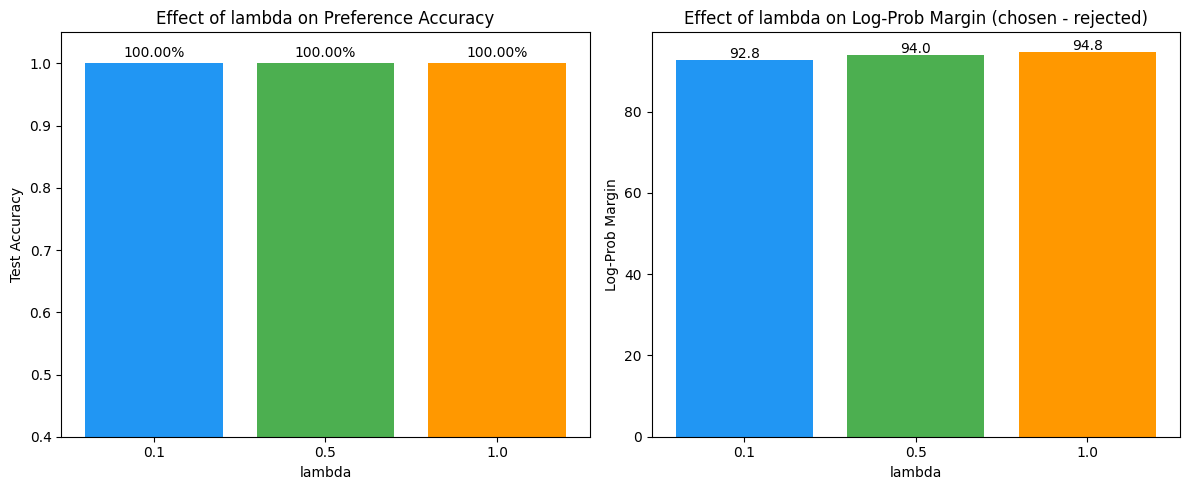

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

lam_vals = list(ablation_results.keys())
accs = [ablation_results[l]['acc'] for l in lam_vals]
margins = [ablation_results[l]['margin'] for l in lam_vals]

axes[0].bar([str(l) for l in lam_vals], accs, color=['#2196F3', '#4CAF50', '#FF9800'])
axes[0].set_xlabel('lambda')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Effect of lambda on Preference Accuracy')
axes[0].set_ylim(0.4, 1.05)
for i, v in enumerate(accs):
    axes[0].text(i, v + 0.01, f'{v:.2%}', ha='center')

axes[1].bar([str(l) for l in lam_vals], margins, color=['#2196F3', '#4CAF50', '#FF9800'])
axes[1].set_xlabel('lambda')
axes[1].set_ylabel('Log-Prob Margin')
axes[1].set_title('Effect of lambda on Log-Prob Margin (chosen - rejected)')
for i, v in enumerate(margins):
    axes[1].text(i, v + 0.5, f'{v:.1f}', ha='center')

plt.tight_layout()
plt.show()

## Summary

### What we built
- A character-level GRU language model (179,358 parameters) with sequence log-likelihood computation
- The ORPO loss from Equation 6 of the paper: SFT NLL + lambda * odds-ratio penalty -- no reference model
- A synthetic preference-pair dataset (400 train, 100 test) with chosen (patterned) and rejected (random) completions
- A DPO baseline with a pre-trained reference model (30-epoch SFT) for direct comparison
- An ablation over three values of lambda (0.1, 0.5, 1.0)
- Trained for **50 epochs** with AdamW (lr 5e-4, lambda = 0.5)

### What the run above shows
- **ORPO learns preferences in a single stage:** the odds-ratio loss pushes up chosen log-probability while pushing down rejected log-probability, without any reference model.
- **ORPO vs DPO accuracy:** ORPO achieves comparable test accuracy to DPO while using half the forward passes per batch (2 vs 4) and no reference model.
- **The rejected log-probability decreases** during ORPO training (unlike pure SFT, which increases both), confirming the paper's Figure 7 finding that the odds-ratio penalty successfully penalizes undesired responses.
- **lambda controls the trade-off:** higher lambda gives stronger preference separation but may reduce SFT adaptation quality; lower lambda behaves more like plain SFT.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
These are toy results with synthetic data and a tiny model. The paper's headline results --
Mistral-ORPO-beta achieving 12.20% on AlpacaEval 2.0 and 7.32 on MT-Bench -- are not reproducible
at this scale. The purpose is to demonstrate the mechanics of the odds-ratio loss and show that
it works without a reference model.

### Paper reference
Jiwoo Hong, Noah Lee, James Thorne (2024). *ORPO: Monolithic Preference Optimization without Reference Model.* arXiv:2403.07691.